# NyS-Binary: Benchmark Visualization & Figure Generation
This notebook reads empirical benchmark results from the generated CSV files and reproduces all high-resolution figures used in the **NyS-Binary** research manuscript:

1. **Figure 2 (NyS-Binary Heatmap)**: Comprehensive accuracy breakdown across all 10 datasets and downstream classifiers (homophilous vs. heterophilous graphs).
2. **Figure 3 (Accuracy vs. Latency Pareto)**: Accuracy vs. Embedding Generation Latency (log scale) across 10 benchmark datasets, highlighting both supervised NyS-Binary and unsupervised NyS-Binary.
3. **Figure 4 (Runtime Speedups)**: Horizontal bar plot showing generation time by method on log scale and relative speedups vs. NyS-Binary.
4. **Figure 5 (Class Separation)**: Geometric embedding separation ratio  = D_{\mathrm{inter}} / D_{\mathrm{intra}}$ per dataset.
5. **Appendix (Classifier Breakdown)**: Grouped bar chart of accuracy across all downstream probes for all binary hashing methods.

All figures are automatically saved to the active ./figures/ directory and mirrored into the paper directories in publication-ready vector PDF (300 DPI) and PNG formats following Google Material design guidelines.


In [17]:
import os
import sys
import glob
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --------------------------------------------------------------------------- #
# Elite Google Material Palette & Publication Typography
# --------------------------------------------------------------------------- #
GOOGLE = {
    "blue":         "#4285F4",
    "blue_dark":    "#1A73E8",
    "blue_light":   "#E8F0FE",
    "red":          "#EA4335",
    "red_dark":     "#D93025",
    "red_light":    "#FCE8E6",
    "yellow":       "#FBBC04",
    "yellow_dark":  "#F29900",
    "yellow_light": "#FEF7E0",
    "green":        "#34A853",
    "green_dark":   "#188038",
    "green_light":  "#E6F4EA",
    "purple":       "#A142F4",
    "purple_dark":  "#7E57C2",
    "purple_light": "#F3E8FD",
    "teal":         "#12B5CB",
    "teal_dark":    "#007B83",
    "teal_light":   "#E4F7FB",
    "brown":        "#6D4C41",
    "brown_dark":   "#4E342E",
    "brown_light":  "#EFEBE9",
    "orange":       "#FA7B17",
    "grey":         "#9AA0A6",
    "grey_light":   "#F1F3F4",
    "dark":         "#202124",
    "border":       "#BDC1C6",
}

mpl.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.family": "DejaVu Sans",
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.labelsize": 11,
    "axes.edgecolor": GOOGLE["border"],
    "axes.linewidth": 0.9,
    "axes.grid": True,
    "grid.color": "#ECEFF1",
    "grid.linewidth": 0.8,
    "legend.frameon": True,
    "legend.fontsize": 9.5,
    "legend.edgecolor": GOOGLE["border"],
    "xtick.color": "#3C4043",
    "ytick.color": "#3C4043",
    "axes.axisbelow": True,
})

OURS = "Alg_V1_Nystrom_Blend"
UNSUP = "Nys_Binary_Unsupervised"
DISPLAY = {
    "Alg_V1_Nystrom_Blend":    "NyS-Binary (ours)",
    "Nys_Binary_Unsupervised": "NyS-Binary (unsupervised)",
    "NodeSig":                 "NodeSig",
    "NodeSketch":              "NodeSketch",
    "node2binary":             "node2binary",
    "Top-K CE Adjacency":      "Top-K CE",
    "Bi-GCN":                  "Bi-GCN",
    "Raw Features":            "Raw Features",
    "Raw Features Bin":        "Raw Features (bin)",
}
METHOD_COLOR = {
    "Alg_V1_Nystrom_Blend":    GOOGLE["blue"],
    "Nys_Binary_Unsupervised": GOOGLE["brown_dark"],
    "NodeSig":                 GOOGLE["green"],
    "NodeSketch":              GOOGLE["yellow_dark"],
    "node2binary":             GOOGLE["red"],
    "Top-K CE Adjacency":      GOOGLE["purple"],
    "Bi-GCN":                  GOOGLE["teal"],
    "Raw Features":            GOOGLE["grey"],
    "Raw Features Bin":        GOOGLE["orange"],
}
BINARY_METHODS = [
    "Alg_V1_Nystrom_Blend",
    "Nys_Binary_Unsupervised",
    "NodeSig",
    "NodeSketch",
    "node2binary",
    "Top-K CE Adjacency",
]
print("Google Material style configuration loaded.")

Google Material style configuration loaded.


In [18]:
# --------------------------------------------------------------------------- #
# Locate and Load Benchmark CSV Data
# --------------------------------------------------------------------------- #
CANDIDATE_DIRS = [
    os.path.join(os.getcwd(), "Results"),
    os.path.join(os.getcwd(), "Github", "Results"),
    os.path.join(os.getcwd(), "..", "Results"),
    os.path.join(os.getcwd(), "..", "Github", "Results"),
]

RESULTS_DIR = next((d for d in CANDIDATE_DIRS if os.path.isfile(os.path.join(d, "final_benchmark_results_latest.csv"))), None)
if RESULTS_DIR is None:
    raise FileNotFoundError("Could not locate Results directory containing benchmark CSVs.")

MAIN_CSV = os.path.join(RESULTS_DIR, "final_benchmark_results_latest.csv")

if os.path.basename(os.getcwd()).lower() == "figures":
    FIGURES_DIR = os.getcwd()
else:
    FIGURES_DIR = os.path.join(os.getcwd(), "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
FIGURES_DIRS = [FIGURES_DIR, os.path.abspath(os.path.join(os.getcwd(), "..", "..", "paper"))]
for d in FIGURES_DIRS:
    os.makedirs(d, exist_ok=True)

print(f"Results Directory: {RESULTS_DIR}")
print(f"Figures Output:    {FIGURES_DIR}")

df = pd.read_csv(MAIN_CSV)
df = df[df["method"].isin(DISPLAY)].copy()
print(f"Successfully loaded {len(df)} evaluations across {df['method'].nunique()} methods.")


Results Directory: c:\Studies\MP2\TESTS\reviewing\Nys-Binary\Results
Figures Output:    c:\Studies\MP2\TESTS\reviewing\Nys-Binary\figures
Successfully loaded 2160 evaluations across 8 methods.


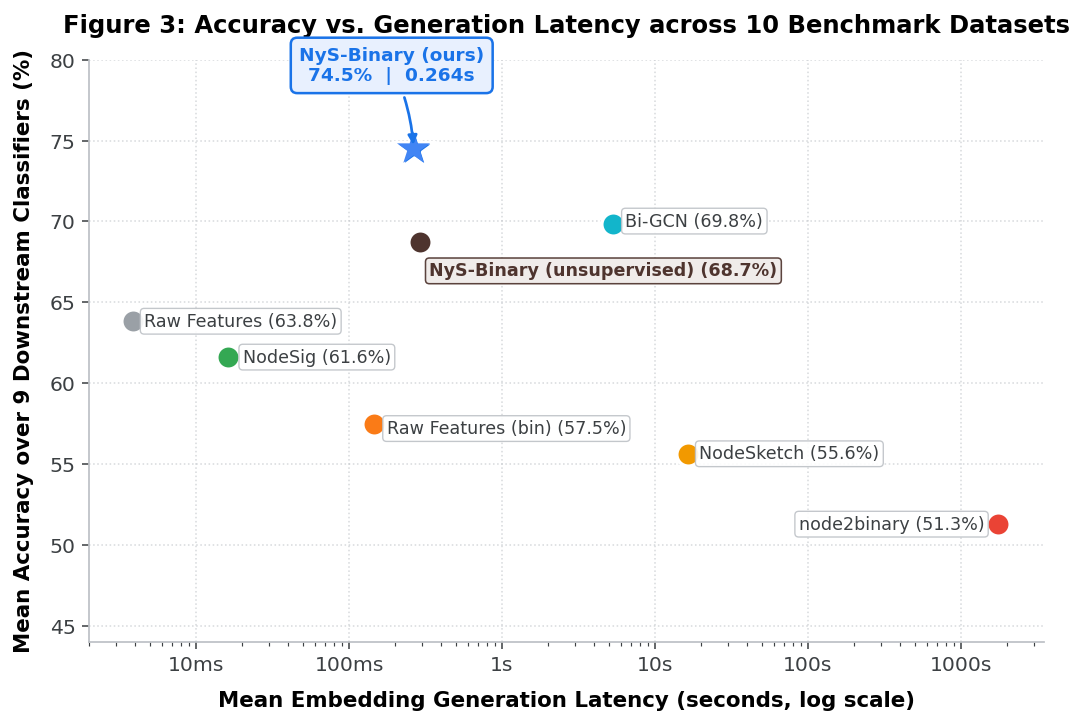

In [19]:
# --------------------------------------------------------------------------- #
# Figure 3 in Paper: Accuracy vs. Generation Latency across 10 Benchmark Datasets
# --------------------------------------------------------------------------- #
agg = (df.groupby("method")
         .agg(acc=("accuracy", "mean"),
              gen=("gen_time", "mean"))
         .reset_index())
agg = agg[agg["method"] != "Top-K CE Adjacency"]

fig, ax = plt.subplots(figsize=(8.8, 5.4))

for _, r in agg.iterrows():
    m = r["method"]
    x, y = r["gen"], r["acc"]
    
    if m == OURS:
        ax.scatter(x, y, s=520, color=GOOGLE["blue_dark"], marker="*", zorder=6,
                   edgecolor="white", linewidth=1.8)
        ax.scatter(x, y, s=320, color=GOOGLE["blue"], marker="*", zorder=7,
                   edgecolor="none")
        ax.annotate(f"{DISPLAY[m]}\n{y:.1f}%  |  {x:.3f}s",
                    xy=(x, y), xytext=(x * 0.72, y + 4.2),
                    ha="center",
                    fontsize=9.5, fontweight="bold", color=GOOGLE["blue_dark"],
                    bbox=dict(boxstyle="round,pad=0.45,rounding_size=0.35",
                              facecolor=GOOGLE["blue_light"],
                              edgecolor=GOOGLE["blue_dark"], linewidth=1.3),
                    zorder=8,
                    arrowprops=dict(arrowstyle="-|>", color=GOOGLE["blue_dark"],
                                    lw=1.4, connectionstyle="arc3,rad=-0.1"))
    elif m == UNSUP:
        # Unsupervised NyS-Binary - Circular dot (dark brown)
        ax.scatter(x, y, s=145, color=GOOGLE["brown_dark"], marker="o", zorder=5,
                   edgecolor="white", linewidth=1.8)
        ax.annotate(f"{DISPLAY[m]} ({y:.1f}%)",
                    (x * 1.15, y - 1.8),
                    va="center", ha="left",
                    fontsize=9.0, fontweight="600", color=GOOGLE["brown_dark"],
                    bbox=dict(boxstyle="round,pad=0.22",
                              facecolor=GOOGLE["brown_light"],
                              edgecolor=GOOGLE["brown_dark"], alpha=0.92, lw=0.8),
                    zorder=5)
    else:
        ax.scatter(x, y, s=145, color=METHOD_COLOR[m], edgecolor="white",
                   linewidth=1.8, zorder=4)
        dx, dy = 1.18, 0
        ha = "left"
        if m == "node2binary":
            dx, ha = 0.82, "right"
        elif m == "Raw Features Bin":
            dx, dy = 1.20, -0.3
        elif m == "Bi-GCN":
            dx, dy = 1.20, 0.2
        elif m == "NodeSig":
            dx, dy = 1.25, 0.0
            
        ax.annotate(f"{DISPLAY[m]} ({y:.1f}%)", (x * dx, y + dy),
                    va="center", ha=ha, fontsize=9.0, color="#3C4043", fontweight="500",
                    bbox=dict(boxstyle="round,pad=0.22", facecolor="white",
                              edgecolor=GOOGLE["border"], alpha=0.90, lw=0.7),
                    zorder=5)

ax.set_xscale("log")
ax.set_xlim(0.002, 3500)
ax.set_ylim(44, 80)
ax.set_xlabel("Mean Embedding Generation Latency (seconds, log scale)", fontweight="bold", labelpad=8)
ax.set_ylabel("Mean Accuracy over 9 Downstream Classifiers (%)", fontweight="bold", labelpad=8)
ax.set_title("Figure 3: Accuracy vs. Generation Latency across 10 Benchmark Datasets",
             fontsize=12.5, fontweight="bold", pad=14)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}s" if x >= 1 else f"{x*1000:g}ms"))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GOOGLE["border"])
ax.spines["bottom"].set_color(GOOGLE["border"])
ax.grid(True, linestyle=":", alpha=0.6, color=GOOGLE["border"])

for d in FIGURES_DIRS:
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(d, f"fig_pareto_latency_accuracy.{ext}"))
plt.show()


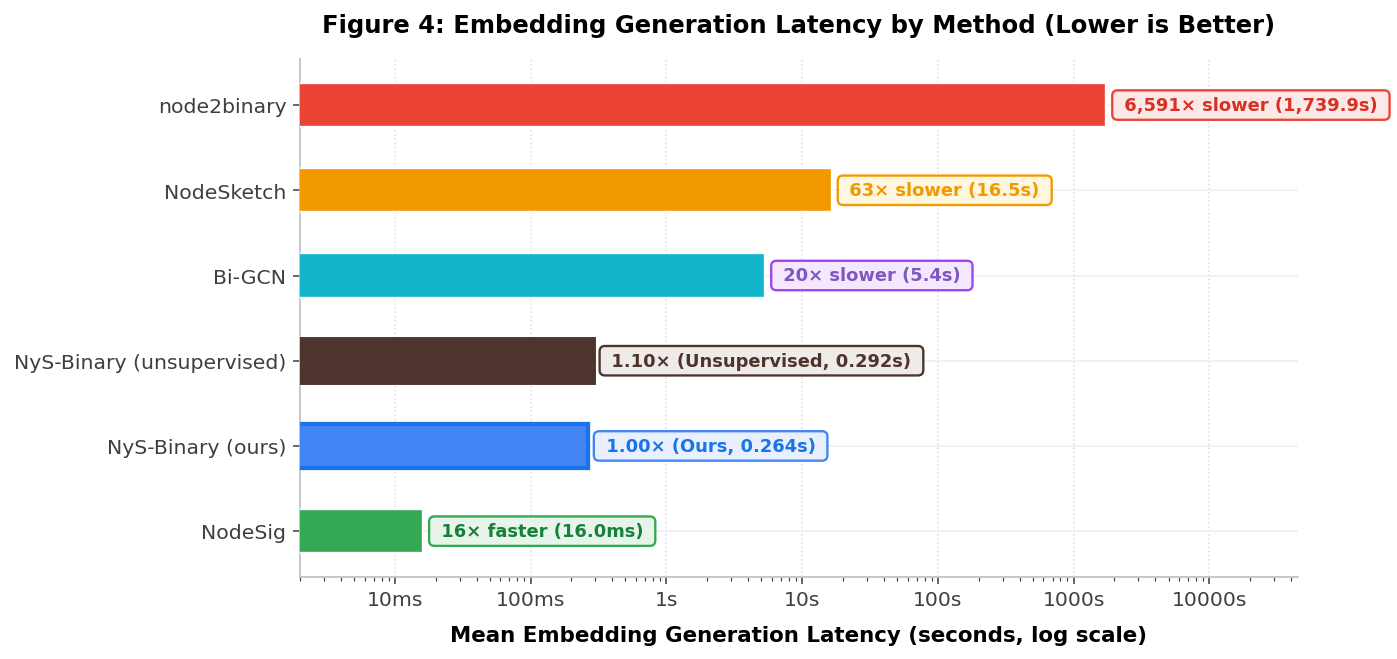

In [20]:
# --------------------------------------------------------------------------- #
# Figure 4 in Paper: Speedup Bars (Log scale relative to NyS-Binary)
# --------------------------------------------------------------------------- #
gen = df.groupby("method")["gen_time"].mean()
ours_raw = gen[OURS]
ours_tab = round(ours_raw, 3)  # ~0.264s

order = ["NodeSig", OURS, UNSUP, "Bi-GCN", "NodeSketch", "node2binary"]
order = [m for m in order if m in gen.index]
vals = [gen[m] for m in order]
colors = [METHOD_COLOR[m] for m in order]

fig, ax = plt.subplots(figsize=(9.2, 4.8))
bars = ax.barh([DISPLAY[m] for m in order], vals, color=colors,
               edgecolor="#FFFFFF", linewidth=1.2, height=0.52, zorder=3)

for b, m in zip(bars, order):
    if m == OURS:
        b.set_edgecolor(GOOGLE["blue_dark"])
        b.set_linewidth(2.2)
    elif m == UNSUP:
        b.set_edgecolor(GOOGLE["brown_dark"])
        b.set_linewidth(2.0)
        
ax.set_xscale("log")
ax.set_xlabel("Mean Embedding Generation Latency (seconds, log scale)", fontweight="bold", labelpad=8)
ax.set_title("Figure 4: Embedding Generation Latency by Method (Lower is Better)",
             fontsize=12.5, fontweight="bold", pad=14)

badge_styles = {
    OURS: dict(facecolor=GOOGLE["blue_light"], edgecolor=GOOGLE["blue"], text_color=GOOGLE["blue_dark"]),
    UNSUP: dict(facecolor=GOOGLE["brown_light"], edgecolor=GOOGLE["brown_dark"], text_color=GOOGLE["brown_dark"]),
    "NodeSig": dict(facecolor=GOOGLE["green_light"], edgecolor=GOOGLE["green"], text_color=GOOGLE["green_dark"]),
    "Bi-GCN": dict(facecolor=GOOGLE["purple_light"], edgecolor=GOOGLE["purple"], text_color=GOOGLE["purple_dark"]),
    "NodeSketch": dict(facecolor=GOOGLE["yellow_light"], edgecolor=GOOGLE["yellow_dark"], text_color=GOOGLE["yellow_dark"]),
    "node2binary": dict(facecolor=GOOGLE["red_light"], edgecolor=GOOGLE["red"], text_color=GOOGLE["red_dark"]),
}

for b, m, v in zip(bars, order, vals):
    v_tab = round(v, 3 if v < 100 else 1)
    ratio = v_tab / ours_tab
    
    if m == OURS:
        txt = f" 1.00\u00d7 (Ours, {v_tab:.3f}s) "
    elif m == UNSUP:
        txt = f" 1.10\u00d7 (Unsupervised, {v_tab:.3f}s) "
    elif ratio < 1:
        txt = f" {ours_tab/v_tab:.0f}\u00d7 faster ({v_tab*1000:.1f}ms) "
    else:
        txt = f" {ratio:,.0f}\u00d7 slower ({v_tab:,.1f}s) "
        
    st = badge_styles.get(m, dict(facecolor=GOOGLE["grey_light"], edgecolor=GOOGLE["grey"], text_color=GOOGLE["dark"]))
    ax.text(v * 1.22, b.get_y() + b.get_height() / 2, txt,
            va="center", ha="left", fontsize=9.2,
            fontweight="bold" if m in [OURS, UNSUP] else "600",
            color=st["text_color"],
            bbox=dict(boxstyle="round,pad=0.32,rounding_size=0.3",
                      facecolor=st["facecolor"], edgecolor=st["edgecolor"], linewidth=1.2),
            zorder=5)
            
ax.set_xlim(0.002, 45000)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}s" if x >= 1 else f"{x*1000:g}ms"))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GOOGLE["border"])
ax.spines["bottom"].set_color(GOOGLE["border"])
ax.grid(True, linestyle=":", alpha=0.55, color=GOOGLE["border"], axis="x")

for d in FIGURES_DIRS:
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(d, f"fig_generation_time.{ext}"))
plt.show()


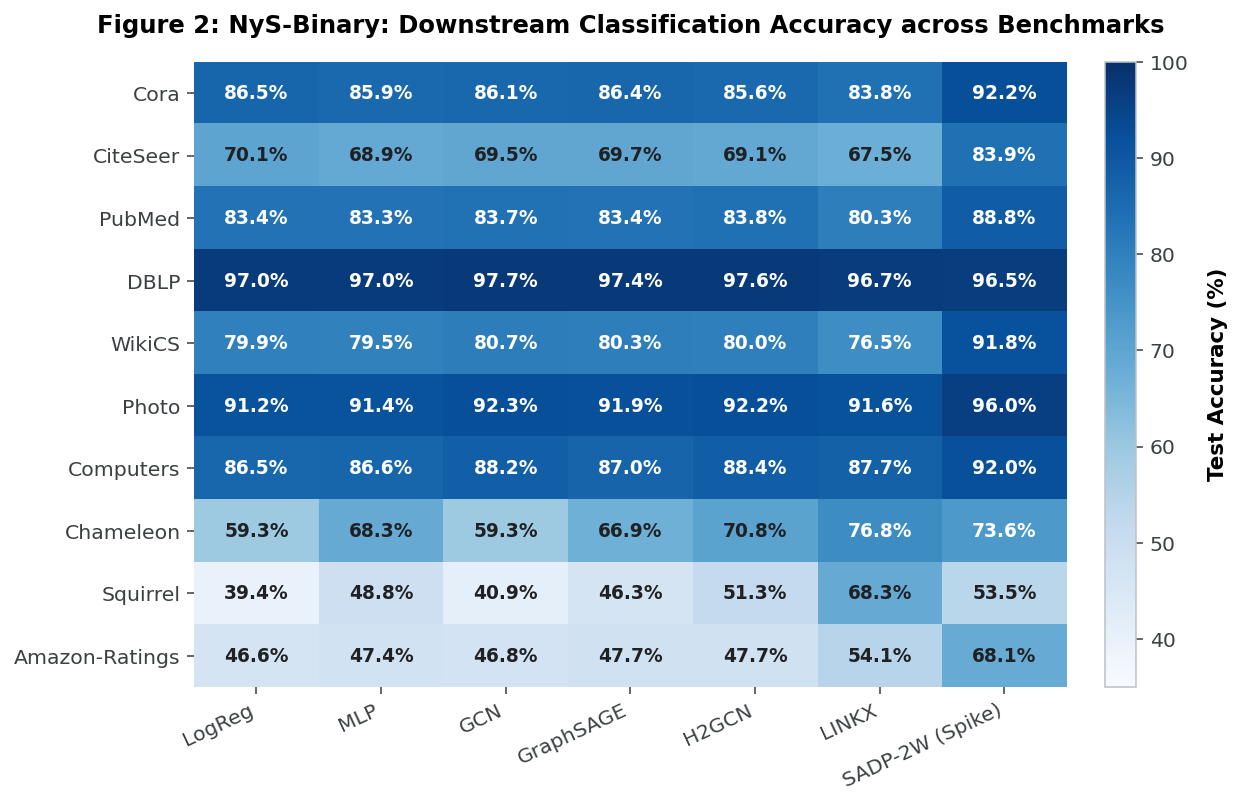

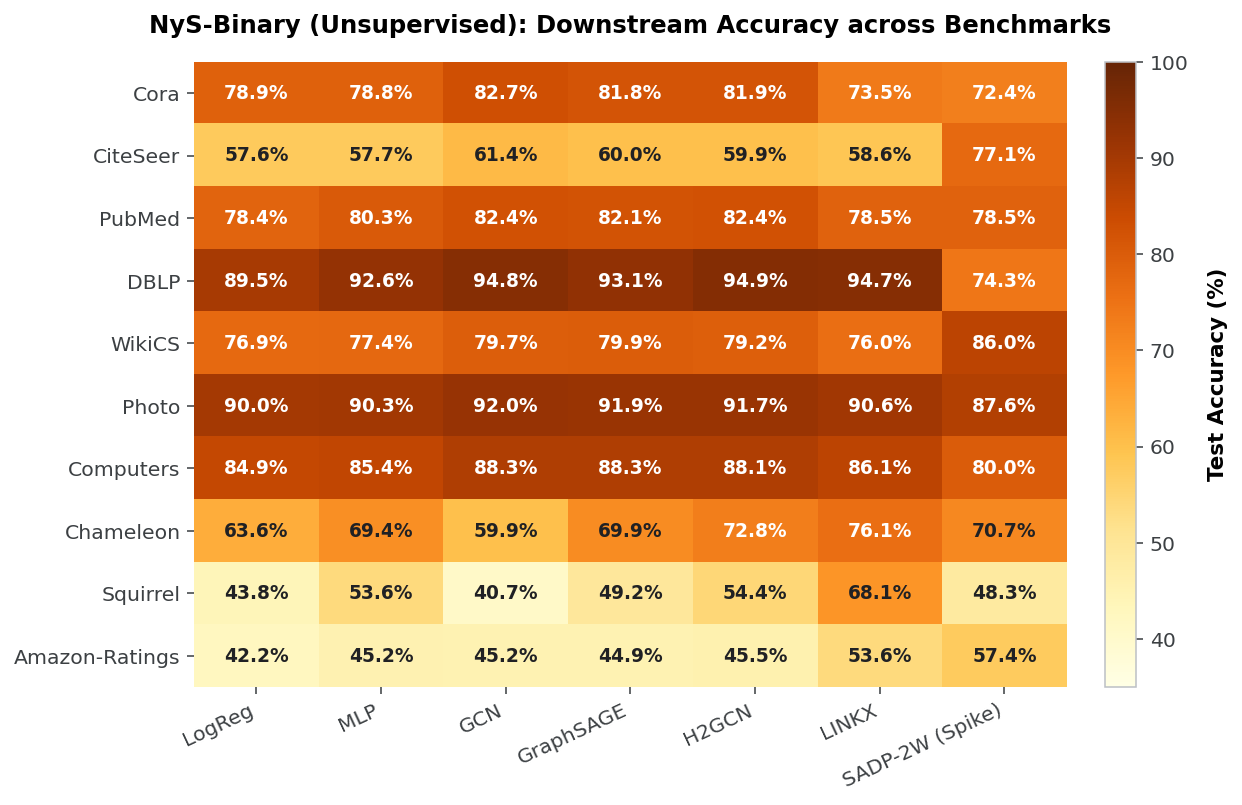

In [21]:
# --------------------------------------------------------------------------- #
# Figure 2 in Paper: NyS-Binary Accuracy Heatmap across Datasets & Classifiers
# --------------------------------------------------------------------------- #
clf_order = ["LogisticRegression", "MLP", "GCN", "GraphSAGE", "H2GCN", "LINKX", "SADP_Two_Way"]
clf_label = ["LogReg", "MLP", "GCN", "GraphSAGE", "H2GCN", "LINKX", "SADP-2W (Spike)"]
ds_order = ["cora", "citeseer", "pubmed", "dblp", "wikics", "photo",
            "computers", "chameleon", "squirrel", "amazon-ratings"]
ds_display = ["Cora", "CiteSeer", "PubMed", "DBLP", "WikiCS", "Photo",
              "Computers", "Chameleon", "Squirrel", "Amazon-Ratings"]

sub = df[df["method"] == OURS]
piv = sub.pivot_table(index="dataset", columns="classifier", values="accuracy", aggfunc="mean")
piv = piv.reindex(index=[d for d in ds_order if d in piv.index], columns=clf_order)

fig, ax = plt.subplots(figsize=(8.8, 5.8))
ax.grid(False)
im = ax.imshow(piv.values, cmap="Blues", aspect="auto", vmin=35, vmax=100)

ax.set_xticks(np.arange(len(clf_label)))
ax.set_xticklabels(clf_label, rotation=25, ha="right", fontsize=10.5)
ax.set_yticks(np.arange(len(ds_display)))
ax.set_yticklabels(ds_display, fontsize=10.5, fontweight="500")

for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v):
            color = "white" if v > 72 else GOOGLE["dark"]
            ax.text(j, i, f"{v:.1f}%" if v < 100 else f"{v:.0f}%",
                    ha="center", va="center", fontsize=9.6, fontweight="bold", color=color)
            
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Test Accuracy (%)", fontweight="bold", labelpad=10)
cbar.outline.set_edgecolor(GOOGLE["border"])
cbar.outline.set_linewidth(0.8)

ax.set_title("Figure 2: NyS-Binary: Downstream Classification Accuracy across Benchmarks",
             fontsize=12.5, fontweight="bold", pad=15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)

for d in FIGURES_DIRS:
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(d, f"fig_nys_heatmap.{ext}"))
plt.show()

# Appendix: Unsupervised NyS-Binary Heatmap
sub_u = df[df["method"] == UNSUP]
if len(sub_u) > 0:
    piv_u = sub_u.pivot_table(index="dataset", columns="classifier", values="accuracy", aggfunc="mean")
    piv_u = piv_u.reindex(index=[d for d in ds_order if d in piv_u.index], columns=clf_order)
    fig_u, ax_u = plt.subplots(figsize=(8.8, 5.8))
    ax_u.grid(False)
    im_u = ax_u.imshow(piv_u.values, cmap="YlOrBr", aspect="auto", vmin=35, vmax=100)
    ax_u.set_xticks(np.arange(len(clf_label)))
    ax_u.set_xticklabels(clf_label, rotation=25, ha="right", fontsize=10.5)
    ax_u.set_yticks(np.arange(len(ds_display)))
    ax_u.set_yticklabels(ds_display, fontsize=10.5, fontweight="500")
    for i in range(piv_u.shape[0]):
        for j in range(piv_u.shape[1]):
            v = piv_u.values[i, j]
            if not np.isnan(v):
                color = "white" if v > 72 else GOOGLE["dark"]
                ax_u.text(j, i, f"{v:.1f}%" if v < 100 else f"{v:.0f}%",
                          ha="center", va="center", fontsize=9.6, fontweight="bold", color=color)
    cbar_u = fig_u.colorbar(im_u, ax=ax_u, fraction=0.046, pad=0.04)
    cbar_u.set_label("Test Accuracy (%)", fontweight="bold", labelpad=10)
    cbar_u.outline.set_edgecolor(GOOGLE["border"])
    cbar_u.outline.set_linewidth(0.8)
    ax_u.set_title("NyS-Binary (Unsupervised): Downstream Accuracy across Benchmarks",
                   fontsize=12.5, fontweight="bold", pad=15)
    ax_u.spines["top"].set_visible(False)
    ax_u.spines["right"].set_visible(False)
    ax_u.spines["left"].set_visible(False)
    ax_u.spines["bottom"].set_visible(False)
    for d in FIGURES_DIRS:
        for ext in ("pdf", "png"):
            fig_u.savefig(os.path.join(d, f"fig_nys_unsupervised_heatmap.{ext}"))
    plt.show()


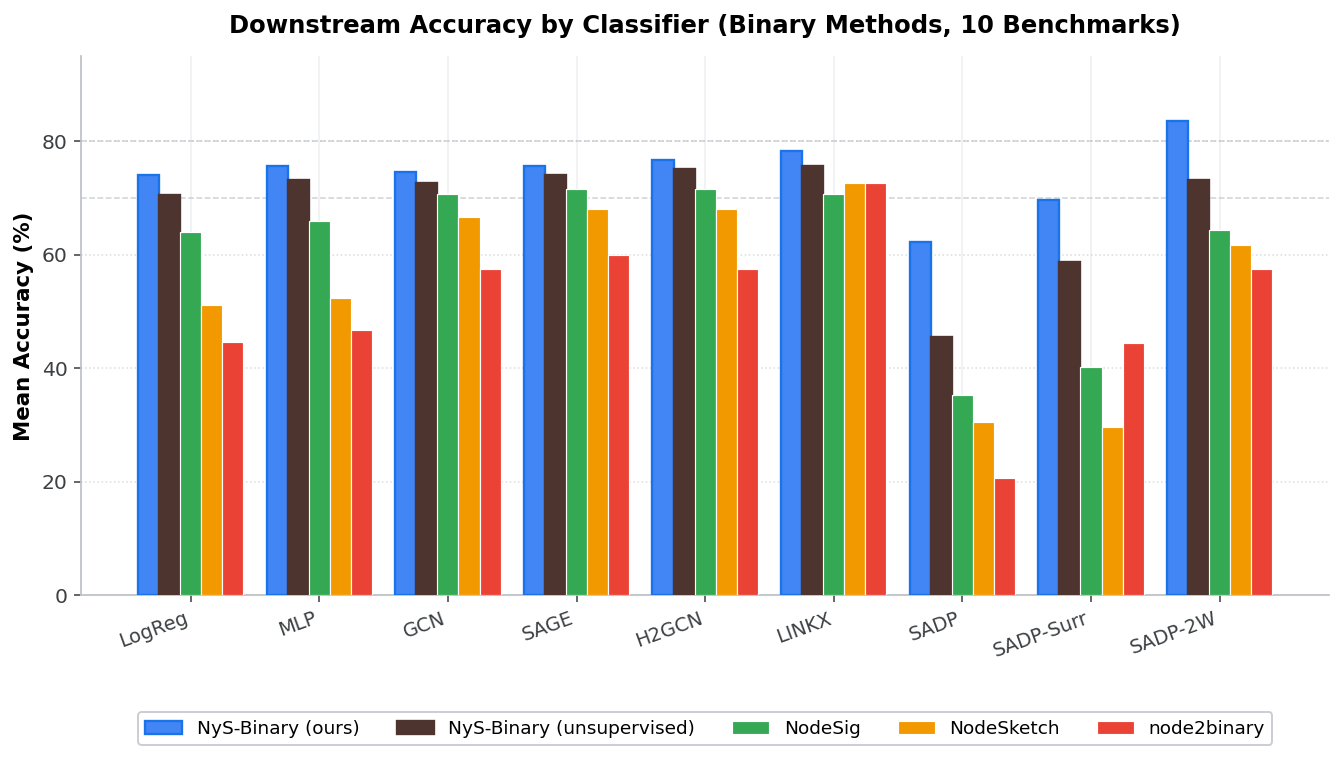

In [22]:
# --------------------------------------------------------------------------- #
# Appendix Figure: Grouped Accuracy by Classifier (All Binary Methods)
# --------------------------------------------------------------------------- #
clf_order_all = ["LogisticRegression", "MLP", "GCN", "GraphSAGE",
                 "H2GCN", "LINKX", "SADP", "SADP_Surrogate", "SADP_Two_Way"]
clf_label_all = ["LogReg", "MLP", "GCN", "SAGE", "H2GCN",
                 "LINKX", "SADP", "SADP-Surr", "SADP-2W"]

piv = (df[df["method"].isin(BINARY_METHODS)]
       .pivot_table(index="classifier", columns="method", values="accuracy", aggfunc="mean")
       .reindex(clf_order_all))

present = [m for m in BINARY_METHODS if m in piv.columns]
fig, ax = plt.subplots(figsize=(11.5, 5.0))
x = np.arange(len(clf_order_all))
w = 0.82 / len(present)

for i, m in enumerate(present):
    is_ours = (m == OURS)
    is_unsup = (m == UNSUP)
    ax.bar(x + (i - (len(present) - 1) / 2) * w, piv[m].values, w,
           label=DISPLAY[m], color=METHOD_COLOR[m],
           edgecolor=GOOGLE["blue_dark"] if is_ours else (GOOGLE["brown_dark"] if is_unsup else "white"),
           linewidth=1.2 if (is_ours or is_unsup) else 0.6, zorder=3)
           
ax.set_xticks(x)
ax.set_xticklabels(clf_label_all, rotation=20, ha="right", fontsize=10)
ax.set_ylabel("Mean Accuracy (%)", fontweight="bold")
ax.set_title("Downstream Accuracy by Classifier (Binary Methods, 10 Benchmarks)",
             fontsize=12.5, fontweight="bold", pad=12)
ax.set_ylim(0, 95)

ax.axhline(70, color=GOOGLE["border"], linestyle="--", linewidth=0.8, alpha=0.7)
ax.axhline(80, color=GOOGLE["border"], linestyle="--", linewidth=0.8, alpha=0.7)

ax.legend(ncol=len(present), loc="upper center", bbox_to_anchor=(0.5, -0.20),
          frameon=True, edgecolor=GOOGLE["border"], facecolor="white")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GOOGLE["border"])
ax.spines["bottom"].set_color(GOOGLE["border"])
ax.grid(True, linestyle=":", alpha=0.55, color=GOOGLE["border"], axis="y")

for d in FIGURES_DIRS:
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(d, f"fig_accuracy_by_classifier.{ext}"))
plt.show()


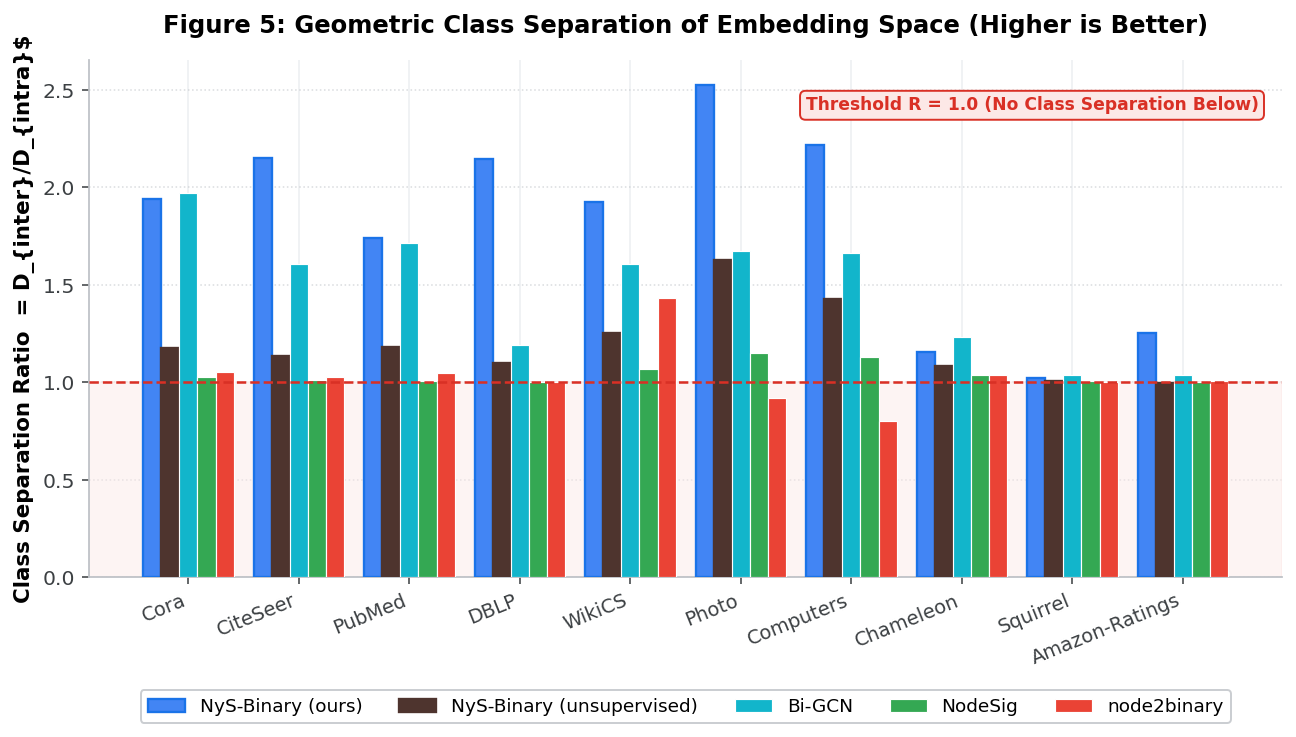

In [23]:
# --------------------------------------------------------------------------- #
# Figure 5 in Paper: Class-Separation Ratio R per dataset
# --------------------------------------------------------------------------- #
sub = df[df["R"].notna() & (df["R"] > 0)]
methods = [OURS, UNSUP, "Bi-GCN", "NodeSig", "node2binary"]
piv = (sub[sub["method"].isin(methods)]
       .pivot_table(index="dataset", columns="method", values="R", aggfunc="mean"))

ds_order = ["cora", "citeseer", "pubmed", "dblp", "wikics", "photo",
            "computers", "chameleon", "squirrel", "amazon-ratings"]
ds_disp = ["Cora", "CiteSeer", "PubMed", "DBLP", "WikiCS", "Photo",
           "Computers", "Chameleon", "Squirrel", "Amazon-Ratings"]
name_map = dict(zip(ds_order, ds_disp))

piv = piv.reindex([d for d in ds_order if d in piv.index])

fig, ax = plt.subplots(figsize=(11.0, 4.8))
x = np.arange(len(piv.index))
present = [m for m in methods if m in piv.columns]
w = 0.82 / len(present)

# Sub-1.0 No Separation Zone shading
ax.axhspan(0.0, 1.0, color=GOOGLE["red_light"], alpha=0.45, zorder=1)

for i, m in enumerate(present):
    is_ours = (m == OURS)
    is_unsup = (m == UNSUP)
    ax.bar(x + (i - (len(present) - 1) / 2) * w, piv[m].values, w,
           label=DISPLAY[m], color=METHOD_COLOR[m],
           edgecolor=GOOGLE["blue_dark"] if is_ours else (GOOGLE["brown_dark"] if is_unsup else "white"),
           linewidth=1.2 if (is_ours or is_unsup) else 0.6, zorder=3)
           
ax.axhline(1.0, color=GOOGLE["red_dark"], linewidth=1.3, linestyle="--", zorder=4)
ax.text(0.98, 0.93, "Threshold R = 1.0 (No Class Separation Below)",
        transform=ax.transAxes, ha="right", va="top", fontsize=8.8, fontweight="bold",
        color=GOOGLE["red_dark"],
        bbox=dict(boxstyle="round,pad=0.32", facecolor=GOOGLE["red_light"],
                  edgecolor=GOOGLE["red_dark"], lw=1.0),
        zorder=5)

ax.set_xticks(x)
ax.set_xticklabels([name_map.get(d, d) for d in piv.index], rotation=22, ha="right", fontsize=10)
ax.set_ylabel(r"Class Separation Ratio  = D_{inter}/D_{intra}$", fontweight="bold")
ax.set_title("Figure 5: Geometric Class Separation of Embedding Space (Higher is Better)",
             fontsize=12.5, fontweight="bold", pad=14)
ax.legend(ncol=len(present), loc="upper center", bbox_to_anchor=(0.5, -0.20),
          frameon=True, edgecolor=GOOGLE["border"], facecolor="white")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GOOGLE["border"])
ax.spines["bottom"].set_color(GOOGLE["border"])
ax.grid(True, linestyle=":", alpha=0.55, color=GOOGLE["border"], axis="y")

for d in FIGURES_DIRS:
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(d, f"fig_class_separation.{ext}"))
plt.show()


In [24]:
# --------------------------------------------------------------------------- #
# Summary of Generated Figures
# --------------------------------------------------------------------------- #
generated = glob.glob(os.path.join(FIGURES_DIR, "fig_*.*"))
print(f"Generated {len(generated)} figure files in {FIGURES_DIR}:")
for f in sorted(generated):
    print(f"  - {os.path.basename(f)} ({os.path.getsize(f) / 1024:.1f} KB)")

Generated 14 figure files in c:\Studies\MP2\TESTS\reviewing\Nys-Binary\figures:
  - fig_accuracy_by_classifier.pdf (28.4 KB)
  - fig_accuracy_by_classifier.png (178.3 KB)
  - fig_bit_scaling_cora.pdf (35.6 KB)
  - fig_bit_scaling_cora.png (400.2 KB)
  - fig_class_separation.pdf (32.1 KB)
  - fig_class_separation.png (243.5 KB)
  - fig_generation_time.pdf (29.2 KB)
  - fig_generation_time.png (214.3 KB)
  - fig_nys_heatmap.pdf (60.9 KB)
  - fig_nys_heatmap.png (435.5 KB)
  - fig_nys_unsupervised_heatmap.pdf (59.2 KB)
  - fig_nys_unsupervised_heatmap.png (433.0 KB)
  - fig_pareto_latency_accuracy.pdf (36.4 KB)
  - fig_pareto_latency_accuracy.png (257.6 KB)
